<h1>Section 4 – Language Models exploration</h1>
In this task, the objective is to harness the capabilities of language models like Bert or Word2Vec, for
supervised learning.
Two interesting concepts play a role when we use neural networks:
1- Itis possible to do transfer learning, i.e., to take a model that have been trained with other
enormous datasets by Big Tech companies, and we can do fine-tuning i.e., to train this model
starting from its pre-trained version.
2- In NLP tasks, words/documents are transformed into vectors (encoding) and this task is
Unsupervised, so we can use a much larger amount of data.
Choose a language model between Bert and Doc2Vec (word2vec for documents), then:
<h2>Perform text embedding on comments</h2>
i.e., body column in data_unsupervised.csv.

<s>a. If you choose Doc2Vec, pretrain Doc2Vec based on the comments. Save the embedding
vectors or model for next steps.</s>

b. If you choose Bert, take the pretrained Bert model like in this example from HuggingFace.
You only need the embedding vectors from the model rather than other down-stream task
capabilities, so just take the base model and extract the embeddings for the following
steps. And you are not required to do fine-tuning here. You can use the Bert, DistillBert
(light version of Bert, smaller, faster), or any other Bert variations.

In [2]:
!pip install transformers
!pip install torch
!pip install imbalanced-learn

  Using cached transformers-4.56.2-py3-none-any.whl.metadata (40 kB)
  Using cached filelock-3.19.1-py3-none-any.whl.metadata (2.1 kB)
  Using cached huggingface_hub-0.35.3-py3-none-any.whl.metadata (14 kB)
  Using cached regex-2025.9.18-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
  Using cached tokenizers-0.22.1-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.8 kB)
  Using cached safetensors-0.6.2-cp38-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.1 kB)
  Using cached hf_xet-1.1.10-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.7 kB)
Using cached transformers-4.56.2-py3-none-any.whl (11.6 MB)
Using cached huggingface_hub-0.35.3-py3-none-any.whl (564 kB)
Using cached hf_xet-1.1.10-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (3.2 MB)
Using cached tokenizers-0.22.1-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (3.3 MB)
Using cached regex-2025.9.18-cp3

In [ ]:
from transformers import DistilBertTokenizer, DistilBertModel
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
import numpy as np

/home/jack/ML4NProject/reddit2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
data = pd.read_csv('data_supervised.csv')
data=data[['author','body','subreddit']].groupby('author').agg(' '.join).reset_index()

In [ ]:
#distilbert smaller but faster model
#uncased -> not case-sensitive

#Load pre-trained tokenizer (vocabulary)
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')
#Load pre-trained model
model = DistilBertModel.from_pretrained('distilbert-base-uncased')
model.eval()

# Function to get embeddings for a list of texts
def get_embeddings(texts, tokenizer, model, max_length=128):
    embeddings = []
    with torch.no_grad():
        count=0 # Just to understand how much time this takes
        for text in texts:
            inputs = tokenizer(text, return_tensors='pt', truncation=True, padding='max_length', max_length=max_length)
            outputs = model(**inputs)
            # Use the [CLS] token embedding as sentence embedding
            cls_embedding = outputs.last_hidden_state[:, 0, :].squeeze().numpy()
            embeddings.append(cls_embedding)
            count += 1
            if count % 10000 == 0:
                print(f"Processed {count} comments")
    return embeddings

# Get embeddings for all comments in 'body'
embeddings = get_embeddings(data['body'].tolist(), tokenizer, model)

<h2>Feature Concatenation.</h2>
For each user, create a feature vector where each column x represents the fraction of times the
user has posted in the x-th subreddit (and reduce the cardinality of the matrix with PCA).
Concatenate the embedding vectors output by the model you chose at step a with these new
features.

In [ ]:
subreddits = data['subreddit'].unique()
user_subreddit_counts = data.groupby(['author', 'subreddit']).size().unstack(fill_value=0)
user_total_comments = user_subreddit_counts.sum(axis=1)
user_sub_fraction = user_subreddit_counts.div(user_total_comments, axis=0)
user_sub_fraction = user_sub_fraction.reindex(columns=subreddits, fill_value=0)

# user_sub_fraction is a DataFrame where rows are users and columns are subreddits,
# and values are the fraction of comments in each subreddit for each user
user_sub_fraction.head()

subreddit,AskReddit tall pics StarWars AskReddit AskReddit,gainit,MouseReview MechanicalKeyboards jailbreak jailbreak jailbreak jailbreak jailbreak jailbreak jailbreak AskReddit,AskWomen AskWomen AskWomen AskWomen AskWomen AskWomen AskWomen AskWomen AskMen,mildlyinteresting todayilearned,tipofmytongue ifyoulikeblank ifyoulikeblank ifyoulikeblank,myfriendwantstoknow,AskReddit,trees trees bestof bestof IAmA,gonewild dirtypenpals dirtypenpals dirtypenpals dirtypenpals AdviceAnimals gifs gifs gifs gifs gifs gifs gifs worldnews worldnews worldnews worldnews worldnews worldnews worldnews worldnews worldnews worldnews worldnews AskReddit AskReddit AskReddit AskReddit AskReddit AskReddit news AskReddit AskReddit AskReddit AskReddit todayilearned AskReddit AskReddit gifs Bad_Cop_No_Donut gonewild gonewild gonewild gonewild gonewild IAmA IAmA WTF WTF WTF WTF WTF,...,feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast mindcrack feedthebeast pcmasterrace pcmasterrace pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace pcmasterrace pcmasterrace feedthebeast feedthebeast feedthebeast feedthebeast pcmasterrace pcmasterrace,TransSpace AskReddit BDSMcommunity AskMen,OkCupid xxketo OkCupid OkCupid OkCupid OkCupid femalefashionadvice AskWomen AskWomen AskWomen AskWomen AskWomen AskWomen amiugly AskWomen amiugly xxketo xxketo xxketo AskWomen AskWomen AskMen MorbidReality AskWomen KitchenConfidential AskReddit AskWomen Baking femalefashionadvice femalefashionadvice UCSantaBarbara food AskWomen AskWomen AskWomen KitchenConfidential KitchenConfidential KitchenConfidential KitchenConfidential KitchenConfidential KitchenConfidential femalefashionadvice,CrossStitch Watches makeupexchange FancyFollicles,AskReddit AskReddit RandomActsOfPolish Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon RandomActsOfPolish RandomActsOfPolish RandomActsOfPolish RandomActsOfPolish RandomActsOfPolish Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Amazon Random_Acts_Of_Am

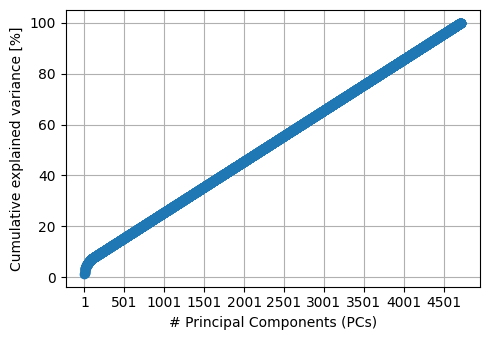

In [ ]:
pca=PCA(random_state=42)
pca=pca.fit(user_sub_fraction)

explained_variance = pca.explained_variance_ratio_
cumul_exp_var = np.cumsum(explained_variance)
perc_cumul_exp_var = cumul_exp_var * 100

# make the plot of cumulative explained variance wrt number of components
plt.figure(figsize=(5, 3.5))
plt.plot(perc_cumul_exp_var, marker='o')
plt.xlabel('# Principal Components (PCs)')
plt.ylabel('Cumulative explained variance [%]')
plt.xticks([i for i in range(0,user_sub_fraction.shape[1],500)], [i for i in range(1,user_sub_fraction.shape[1]+1,500)])
plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
pca=PCA(random_state=42,n_components=3500)
pca=pca.fit(user_sub_fraction)
X_pca=pca.transform(user_sub_fraction)

In [ ]:
# Convert X_pca to DataFrame
X_pca_df = pd.DataFrame(X_pca, index=user_sub_fraction.index)

# Convert embeddings to DataFrame
embeddings_df = pd.DataFrame(embeddings)
embeddings_df.index = user_sub_fraction.index  # Align indices with user_sub_fraction
# Concatenate PCA features and embeddings
X_combined = pd.concat([X_pca_df, embeddings_df], axis=1)

X_combined.to_csv('X_combined.csv')
#X_combined = embeddings_df


<h2>3. Build and fine-tune a classification model.</h2>
a. Build a basic multilayer perceptron (MLP) to perform classification based on the
concatenated features at the previous step. Fine-tune it on the supervised training set for N
epochs, like what you did in Section 2.

b. Plot the learning curves on training and validation set. After how many epochs should we
stop the training?

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc, precision_recall_curve, average_precision_score

import torch
from torch import nn
import torch.nn.functional as F

In [4]:
try:
    del data, embeddings, pca, subreddits, user_sub_fraction, user_subreddit_counts, user_total_comments, X_pca
except NameError:
    pass

X_combined = pd.read_csv('X_combined.csv', index_col=0)
target_df=pd.read_csv('target_supervised.csv')
target_df = target_df.set_index('author').loc[X_combined.index].reset_index()

X_train, X_test, y_train, y_test = train_test_split(X_combined, target_df['gender'], stratify=target_df['gender'], train_size=0.85, random_state=15)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, stratify=y_train, train_size=0.7/0.85, random_state=15)

print(X_train.shape, X_val.shape, X_test.shape)

scaler = StandardScaler()
scaler.fit(X_train)
X_train_s, X_val_s, X_test_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

X_train = torch.tensor(X_train_s, dtype=torch.float)
y_train = torch.tensor(y_train.values, dtype=torch.long)
X_val = torch.tensor(X_val_s, dtype=torch.float)
y_val = torch.tensor(y_val.values, dtype=torch.long)
X_test = torch.tensor(X_test_s, dtype=torch.float)
y_test = torch.tensor(y_test.values, dtype=torch.long)

(3500, 4268) (750, 4268) (750, 4268)


In [5]:
# define the function that calculate the accuracy
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred))
    return acc

# function to compute and plot the confusion matrix
def confusion_matrix(y_true, y_pred):
    df = pd.DataFrame([x for x in zip([x.item() for x in y_true], [x.item() for x in y_pred])], columns=['y_true', 'y_pred'])
    df[['samples']] = 1
    confusion = pd.pivot_table(df, index='y_true', columns='y_pred', values='samples', aggfunc=sum)
    plt.figure()
    sns.heatmap(confusion, cmap='Blues', annot=True, cbar_kws={'label':'Occurrences'}, fmt='g')
    plt.xlabel('Prediction')
    plt.ylabel('True')    
    plt.title('Confusion matrix')
    plt.show()

In [6]:
# Define the neural network
class Model_classification(nn.Module): 
    def __init__(
        self, 
        in_features, # number of input features
        out_features, # number of output features
        hidden_1, # number of neurons in the 1st hidden layer
        hidden_2, # number of neurons in the 2nd hidden layer
        hidden_3 # number of neurons in the 3rd hidden layer
    ):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=in_features, out_features=hidden_1) # 1st linear layer
        self.layer_2 = nn.Linear(in_features=hidden_1, out_features=hidden_2) # 2nd linear layer
        self.layer_3 = nn.Linear(in_features=hidden_2, out_features=hidden_3) # 3rd linear layer

        self.layer_output = nn.Linear(in_features=hidden_3, out_features=out_features) # output layer
        self.activation_1 = nn.Tanh() # activation function
        self.activation_2 = nn.Softmax(dim=1) # activation function
        self.activation_3 = nn.LeakyReLU() # activation function

    # define feedforward process
    def forward(self, x):
        #x = x.flatten(start_dim=1) #to go from 28x28 image tensor to 784 input tensor
        out = self.activation_3(self.layer_1(x)) #output of 1st hidden layer
        out = self.activation_3(self.layer_2(out)) #output of 2nd hidden layer
        out = self.activation_3(self.layer_3(out))
        out = self.activation_2(self.layer_output(out)) #output of the nn
        #out = self.layer_output(out) 
        
        return out

In [7]:
torch.manual_seed(8)
dim_features = X_combined.shape[1]
model = Model_classification(
    in_features = dim_features, 
    out_features = 2, 
    hidden_1 = dim_features, 
    #hidden_1 = 1000,
    hidden_2 = int(dim_features/2),
    #hidden_2=500,
    hidden_3 = int(dim_features/4)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=5e-6) 

In [8]:
def create_batches(data, labels, batch_size):
    num_samples = data.shape[0]
    batches = []
    for i in range(0, num_samples, batch_size):
        data_batch = data[i:i + batch_size]
        label_batch = labels[i:i + batch_size]
        batches.append((data_batch, label_batch))
    return batches
    
# create the batches for training set
batch_size = 64 # you can choose other batch numbers
batches = create_batches(X_train, y_train, batch_size)

In [9]:
import itertools

# Define parameter grid
param_grid = {
    'learning_rate': [1e-4, 1e-5],
    'hidden_1': [1000,  2000],
    'hidden_2': [1500, 750, 2500],
    'hidden_3': [250, 500, 1000],
    'batch_size': [64]
}

# Generate all combinations
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0
best_params = None

for params in param_combinations:
    # Create model with current parameters
    model = Model_classification(
        in_features=dim_features,
        out_features=2,
        hidden_1=params['hidden_1'],
        hidden_2=params['hidden_2'],
        hidden_3=params['hidden_3']
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'])
    batch_size = params['batch_size']
    batches = create_batches(X_train, y_train, batch_size)

    epoch = 0
    current_max_acc = 0
    stop = False
    max_cumulated_epochs = 5
    current_cumulated_epochs = 0
    
    while not stop:
        # model training phase
        model.train()
        for _, (data_batch, label_batch) in enumerate(batches):
            y_prob = model(data_batch).squeeze() # get the output probability of predictions
            loss_batch = loss_fn(y_prob, label_batch) # calculate the loss
            optimizer.zero_grad() # reset the gradients of model parameters
            loss_batch.backward() # backpropagate the prediction loss
            optimizer.step() # adjust the parameters by the gradients 

        # model evaluation phase
        model.eval()
        
        # training set
        y_prob = model(X_train).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) # get the label
        acc_train = accuracy_fn(y_true=y_train, y_pred=y_pred)

        # validation set
        y_prob = model(X_val).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) 
        acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)

        if current_max_acc -  acc_val < 0: 
            current_max_acc =  acc_val
        else:
            current_cumulated_epochs += 1
            if current_cumulated_epochs >= max_cumulated_epochs:
                stop = True

        if acc_train==1.0:
            stop=True

    print(f"Params: {params}, Val Acc: {acc_val:.4f}")
    if acc_val > best_val_acc:
        best_val_acc = acc_val
        best_params = params

print("Best parameters:", best_params)

Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7440
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 64}, Val Acc: 0.7453
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 64}, Val Acc: 0.7267
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7480
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 500, 'batch_size': 64}, Val Acc: 0.7493
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 1000, 'batch_size': 64}, Val Acc: 0.7360
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 2500, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7573
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 2500, 'hidden_3': 500, 'batch_size': 64}, Val Acc: 0.7653
Params: {'learning_rate':

In [10]:
# Train the model with the best parameters found in best_params
model = Model_classification(
    in_features=dim_features,
    out_features=2,
    hidden_1=best_params['hidden_1'],
    hidden_2=best_params['hidden_2'],
    hidden_3=best_params['hidden_3']
)
optimizer = torch.optim.Adam(model.parameters(), lr=best_params['learning_rate'])

batch_size = best_params['batch_size']
batches = create_batches(X_train, y_train, batch_size)

epoch=0
loss_train_all = []
loss_val_all = []
acc_train_all = []
acc_val_all = []
current_max_acc = 0
current_cumulated_epochs = 0
max_cumulated_epochs = 3
stop = False

while not stop:
    # Training phase
    model.train()
    loss_all = []
    for data_batch, label_batch in batches:
        y_prob = model(data_batch)
        loss = loss_fn(y_prob, label_batch)
        loss_all.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Evaluation phase
    model.eval()
    with torch.no_grad():
        # Training set
        y_prob_train = model(X_train)
        y_pred_train = torch.argmax(y_prob_train, dim=1)
        acc_train = accuracy_fn(y_train, y_pred_train)
        
        # Validation set
        y_prob_val = model(X_val)
        loss_val = loss_fn(y_prob_val, y_val)
        y_pred_val = torch.argmax(y_prob_val, dim=1)
        acc_val = accuracy_fn(y_val, y_pred_val)
    
    # Collect results
    loss_train_all.append(np.mean(loss_all))
    loss_val_all.append(loss_val.item())
    acc_train_all.append(acc_train)
    acc_val_all.append(acc_val)
    
    print(f'Epoch: {epoch+1} | Train Loss: {loss_train_all[-1]:.5f}, Val Loss: {loss_val_all[-1]:.5f}, Train Acc: {acc_train:.4f}, Val Acc: {acc_val:.4f}')
    epoch += 1

    # if the evaluated accuracy is not larger than the maximum accuracy recorded, we increase the cumulation of epochs of 1
    if current_max_acc -  acc_val < 0: 
        current_max_acc =  acc_val
    else:
        current_cumulated_epochs += 1
        if current_cumulated_epochs >= max_cumulated_epochs:
            stop = True

Epoch: 1 | Train Loss: 0.62989, Val Loss: 0.59502, Train Acc: 0.7300, Val Acc: 0.7307
Epoch: 2 | Train Loss: 0.57845, Val Loss: 0.57504, Train Acc: 0.7300, Val Acc: 0.7307
Epoch: 3 | Train Loss: 0.56301, Val Loss: 0.56657, Train Acc: 0.7300, Val Acc: 0.7307
Epoch: 4 | Train Loss: 0.54558, Val Loss: 0.55485, Train Acc: 0.7346, Val Acc: 0.7333
Epoch: 5 | Train Loss: 0.51708, Val Loss: 0.53873, Train Acc: 0.8357, Val Acc: 0.7653
Epoch: 6 | Train Loss: 0.47516, Val Loss: 0.52742, Train Acc: 0.9020, Val Acc: 0.7813
Epoch: 7 | Train Loss: 0.42756, Val Loss: 0.52461, Train Acc: 0.9449, Val Acc: 0.7827
Epoch: 8 | Train Loss: 0.38491, Val Loss: 0.52478, Train Acc: 0.9669, Val Acc: 0.7800


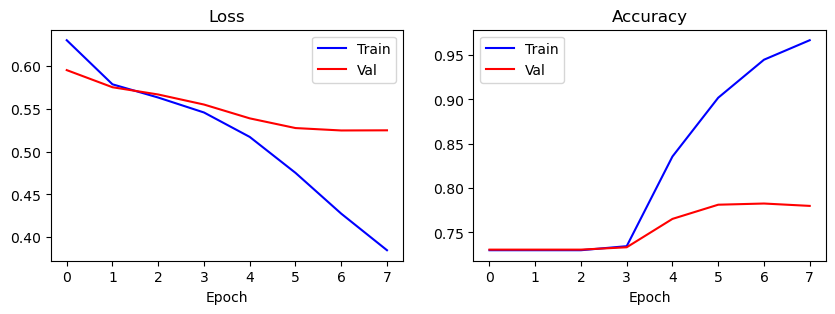

In [11]:
# visualize the evolution of losses and accuracies

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10,3))

ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.plot(loss_train_all, label='Train', color='blue')
ax1.plot(loss_val_all, label='Val', color='red')
ax1.legend()

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.plot(acc_train_all, label='Train', color='blue')
ax2.plot(acc_val_all, label='Val', color='red')
ax2.legend()

plt.show()

The accuracy is: 0.78


/tmp/ipykernel_56/3612716615.py:11: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  confusion = pd.pivot_table(df, index='y_true', columns='y_pred', values='samples', aggfunc=sum)


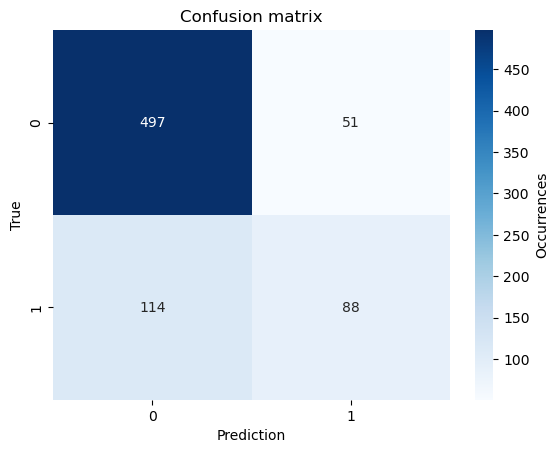

In [12]:
# visualize (final) confusion matrix on validation set

y_prob = model(X_val).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)
print('The accuracy is:', acc_val)
confusion_matrix(y_val, y_pred)

The accuracy is: 0.7853333333333333


/tmp/ipykernel_56/3612716615.py:11: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  confusion = pd.pivot_table(df, index='y_true', columns='y_pred', values='samples', aggfunc=sum)


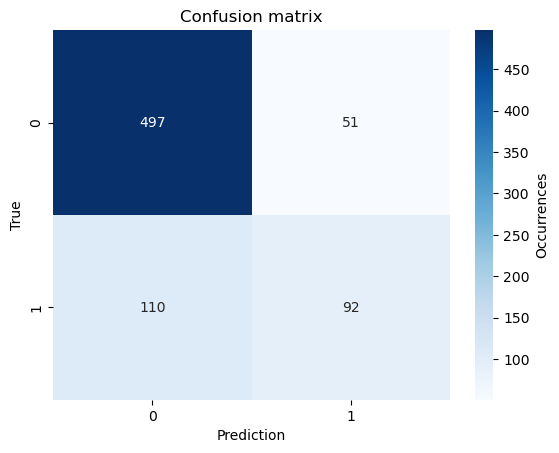

In [13]:
# visualize (final) confusion matrix on test set
y_prob = model(X_test).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_test = accuracy_fn(y_true=y_test, y_pred=y_pred)
print('The accuracy is:', acc_test)
confusion_matrix(y_test, y_pred)

Precision: 0.6434
Recall:    0.4554
F1-score:  0.5333
Class 0 - Precision: 0.8188, Recall: 0.9069, F1-score: 0.8606
Class 1 - Precision: 0.6434, Recall: 0.4554, F1-score: 0.5333


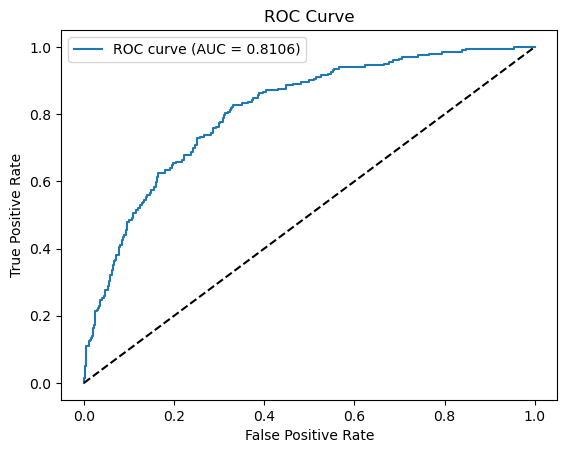

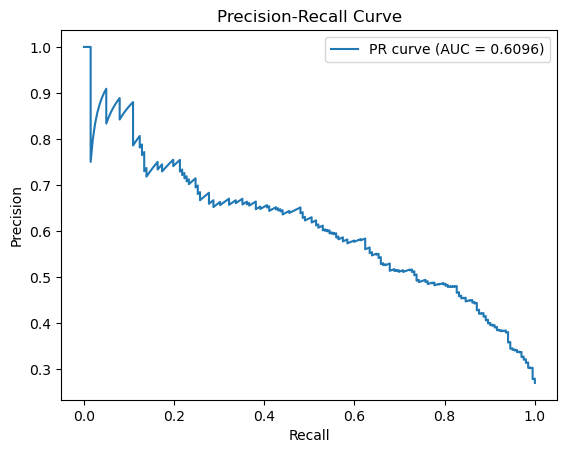

In [15]:
# Convert torch tensors to numpy arrays
y_test_np = y_test.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average='binary')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, y_prob_np)
pr_auc = average_precision_score(y_test_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()